<a href="https://colab.research.google.com/github/donggeunlee77/chest-CT-DL/blob/main/MONAItutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. kaggle에서 권장되는 위쪽 방식 API token을 생성한다음 key값을 복사한다
2. Colab 왼쪽 사이드바에서 🔑 아이콘(Secrets) 클릭하여 보안비밀(Secret) 설정
  이름: KAGGLE_API_TOKEN
  값: 방금 발급받은 API Token
  Notebook access 활성화

3. 아래 코드 실행

In [ ]:
!pip install -q -U kaggle

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

위에서 좌측의 "KAGGLE_API_TOKEN"은 Kaggle CLI가 인식하는 환경변수 이름 이므로 변경하지 말것, 우측의 "KAGGLE_API_TOKEN"은 내가 설정한 이름.

In [ ]:
!kaggle competitions list -s osic

ref                                                                      deadline             category       reward  teamCount  userHasEntered  userRank  
-----------------------------------------------------------------------  -------------------  ---------  ----------  ---------  --------------  --------  
https://www.kaggle.com/competitions/osic-pulmonary-fibrosis-progression  2020-10-06 23:59:00  Featured   55,000 Usd       2097            True         0  
https://www.kaggle.com/competitions/deteccin-de-posiciones-de-yoga       2021-07-11 04:00:00  Community       Kudos         22           False         0  
https://www.kaggle.com/competitions/tkaicompetition                      2022-10-16 23:59:00  Community       Kudos          0           False         0  


In [ ]:
!kaggle competitions download -c osic-pulmonary-fibrosis-progression

100% 13.3G/13.3G [12:16<00:00, 19.5MB/s]



In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   14G  100G  12% /


!df -h /content는 Google Colab의 /content 디렉터리가 위치한 디스크의 저장 공간 상태를 확인하는 명령어야.

각 부분을 분해해 보면 다음과 같아.
명령어	의미
!	Colab에서 Python이 아닌 Linux 셸 명령어를 실행
df	disk free. 디스크의 용량 및 여유 공간 확인
-h	human-readable. 용량을 GB, MB 등 읽기 쉬운 단위로 표시
/content	확인할 디렉터리 경로


In [ ]:
!ls -lh /content/

total 14G
-rw-r--r-- 1 root root  14G Jul 10  2020 osic-pulmonary-fibrosis-progression.zip
drwxr-xr-x 1 root root 4.0K Nov  6 16:54 sample_data


!ls -lh /content/는 /content/ 폴더 안에 어떤 파일과 폴더가 있는지, 각각의 크기가 얼마인지 확인하는 명령어야.

각 부분을 분해하면 다음과 같아.
명령어	의미
!	Linux 셸 명령어 실행
ls	list. 파일 및 폴더 목록 출력
-l	long format. 상세 정보 출력
-h	human-readable. 파일 크기를 KB, MB, GB로 표시
/content/	확인할 폴더 경로

In [ ]:
!du -h /content/osic-pulmonary-fibrosis-progression.zip

14G	/content/osic-pulmonary-fibrosis-progression.zip


!du -h /content/osic-pulmonary-fibrosis-progression.zip는 해당 ZIP 파일이 실제로 차지하는 디스크 용량을 확인하는 명령어야.

각 부분을 분해하면 다음과 같아.
명령어	의미
!	Linux 셸 명령어 실행
du	disk usage. 디스크 사용량 확인
-h	사람이 읽기 쉬운 단위로 표시
/content/osic-pulmonary-fibrosis-progression.zip	용량을 확인할 대상 파일

In [ ]:
!mkdir -p /content/osic
!unzip -q /content/osic-pulmonary-fibrosis-progression.zip -d /content/osic

mkdir	make directory. 폴더 생성
-p	폴더가 이미 있어도 오류를 내지 않음. 상위 폴더도 필요하면 생성
/content/osic	생성할 폴더 경로

unzip	ZIP 압축 해제 프로그램
-q	quiet. 압축 해제 과정의 상세 출력 생략
.zip 경로	압축을 해제할 원본 파일
-d	destination. 압축 해제할 목적지 지정
/content/osic	압축 해제된 파일을 저장할 폴더

In [ ]:
import numpy as np
import pandas as pd
import os
import json
from pathlib import Path
from glob import glob
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array
from keras import models, regularizers, layers, optimizers, losses, metrics
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical
from keras.preprocessing.image import img_to_array
from keras.preprocessing import image

##

In [ ]:
data_path = Path('/content/osic/')
train_path = data_path / 'train'
test_path = data_path / 'test'
print(train_path, test_path)

/content/osic/train /content/osic/test


In [ ]:
!ls /content/osic/

sample_submission.csv  test  test.csv  train  train.csv


In [ ]:
!pip install pydicom
import pydicom
from pydicom.data import get_testdata_files
print(__doc__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 72.3 MB/s  0:00:00
Automatically created module for IPython interactive environment


In [ ]:
PathDicom = '/content/osic/'
lstFilesDCM = []
for dirName, subdirList, fileList in os.walk(PathDicom):
  for filename in fileList:
    if '.dcm' in filename.lower():
      lstFilesDCM.append(os.path.join(dirName,filename))

os.walk()는 지정한 폴더 내부를 재귀적으로 탐색하는 Python 함수야.

반환하는 세 가지 변수를 이해하면 돼.
변수	의미
dirName	현재 탐색 중인 폴더의 경로
subdirList	현재 폴더 바로 아래에 있는 하위 폴더 목록
fileList	현재 폴더에 들어 있는 파일 목록

In [ ]:
print(lstFilesDCM[0])

/content/osic/train/ID00138637202231603868088/254.dcm


In [ ]:
RefDs = pydicom.dcmread(lstFilesDCM[0])
RefDs

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 200
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 2.25.16663707084367946016506162900541388003
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.1
(0002,0013) Implementation Version Name         SH: 'OSIRIX_361'
(0002,0016) Source Application Entity Title     AE: 'ANONYMOUS'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL', 'CT_SOM5 SPI']
(0008,0018) SOP Instance UID                    UI: 2.25.16663707084367946016506162900541388003
(0008,0060) Modality                            CS: 'CT'
(0008,0070

In [ ]:
ConstPixelDims = (int(RefDs.Rows), int(RefDs.Columns), len(lstFilesDCM))
print(ConstPixelDims)

(512, 512, 34287)


In [ ]:
pat_name = RefDs.PatientName
display_name = pat_name.family_name + ", " + pat_name.given_name
print("Patient's name................:", display_name)
print("Patient id....................:", RefDs.PatientID)
print("Modality......................:", RefDs.Modality)
print("BodyPartExamined..............:", RefDs.BodyPartExamined)
print("Image Position    (Patient)...:", RefDs.ImagePositionPatient)
print("Image Orientation (Patient)...:", RefDs.ImageOrientationPatient)

Patient's name................: ID00138637202231603868088, 
Patient id....................: ID00138637202231603868088
Modality......................: CT
BodyPartExamined..............: Chest
Image Position    (Patient)...: [-198.615234375, -392.115234375, -248]
Image Orientation (Patient)...: [1, 0, 0, 0, 1, 0]


In [ ]:
if 'PixelData' in RefDs:
  rows = int(RefDs.Rows)
  cols = int(RefDs.Columns)
  print("Image size...: {rows:d} x {cols:d}, {size:d} bytes".format(rows=rows, cols=cols, size=len(RefDs.PixelData)))
  if "PixelSpacing" in RefDs:
    print("Pixel spacing...:", RefDs.PixelSpacing)

print("Slice location...:", RefDs.get('SliceLocation', "(missing)"))

Image size...: 512 x 512, 524288 bytes
Pixel spacing...: [0.76953125, 0.76953125]
Slice location...: 248


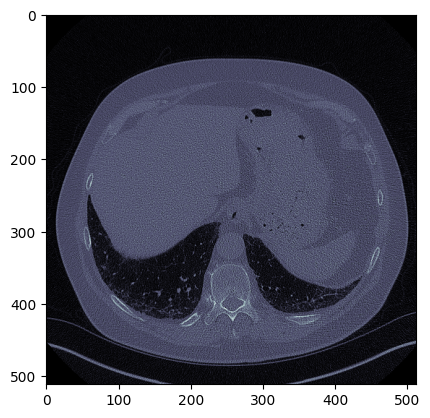

In [ ]:
plt.imshow(RefDs.pixel_array, cmap=plt.cm.bone)
plt.show()

In [ ]:
data = pd.read_csv(data_path / 'test.csv')
data

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus
0,ID00419637202311204720264,6,3020,70.186855,73,Male,Ex-smoker
1,ID00421637202311550012437,15,2739,82.045291,68,Male,Ex-smoker
2,ID00422637202311677017371,6,1930,76.672493,73,Male,Ex-smoker
3,ID00423637202312137826377,17,3294,79.258903,72,Male,Ex-smoker
4,ID00426637202313170790466,0,2925,71.824968,73,Male,Never smoked


In [ ]:
data.loc[data['Patient'] == 'ID00422637202311677017371']

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus
2,ID00422637202311677017371,6,1930,76.672493,73,Male,Ex-smoker


In [ ]:
dim = 25
size = 6
data2Dlist = [[0 for x in range(size)] for y in range(dim)]

In [ ]:
data2Dlist

[[0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0]]

In [ ]:
for i in range(0,dim):
  print(i, lstFilesDCM[i])
  data2Dlist[i][0] = pydicom.dcmread(lstFilesDCM[i]).PatientID
  data2Dlist[i][1] = pydicom.dcmread(lstFilesDCM[i]).Modality
  data2Dlist[i][2] = pydicom.dcmread(lstFilesDCM[i]).BodyPartExamined
  data2Dlist[i][3] = pydicom.dcmread(lstFilesDCM[i]).InstanceNumber
  data2Dlist[i][4] = '73'
  data2Dlist[i][5] = 'male'
data2Dlist

0 /content/osic/train/ID00138637202231603868088/254.dcm
1 /content/osic/train/ID00138637202231603868088/225.dcm
2 /content/osic/train/ID00138637202231603868088/178.dcm
3 /content/osic/train/ID00138637202231603868088/92.dcm
4 /content/osic/train/ID00138637202231603868088/281.dcm
5 /content/osic/train/ID00138637202231603868088/247.dcm
6 /content/osic/train/ID00138637202231603868088/201.dcm
7 /content/osic/train/ID00138637202231603868088/214.dcm
8 /content/osic/train/ID00138637202231603868088/272.dcm
9 /content/osic/train/ID00138637202231603868088/121.dcm
10 /content/osic/train/ID00138637202231603868088/74.dcm
11 /content/osic/train/ID00138637202231603868088/207.dcm
12 /content/osic/train/ID00138637202231603868088/2.dcm
13 /content/osic/train/ID00138637202231603868088/104.dcm
14 /content/osic/train/ID00138637202231603868088/47.dcm
15 /content/osic/train/ID00138637202231603868088/137.dcm
16 /content/osic/train/ID00138637202231603868088/33.dcm
17 /content/osic/train/ID0013863720223160386808

[['ID00138637202231603868088', 'CT', 'Chest', '254', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '225', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '178', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '92', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '281', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '247', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '201', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '214', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '272', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '121', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '74', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '207', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '2', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '104', '73', 'male'],
 ['ID00138637202231603868088', 'CT', 'Chest', '47', 

In [ ]:
df = pd.DataFrame(data2Dlist, columns=['ID','Modality','BPE','Slice','Age','Sex'])
df

,ID,Modality,BPE,Slice,Age,Sex
0,ID00138637202231603868088,CT,Chest,254,73,male
1,ID00138637202231603868088,CT,Chest,225,73,male
2,ID00138637202231603868088,CT,Chest,178,73,male
3,ID00138637202231603868088,CT,Chest,92,73,male
4,ID00138637202231603868088,CT,Chest,281,73,male
5,ID00138637202231603868088,CT,Chest,247,73,male
6,ID00138637202231603868088,CT,Chest,201,73,male
7,ID00138637202231603868088,CT,Chest,214,73,male
8,ID00138637202231603868088,CT,Chest,272,73,male
9,ID00138637202231603868088,CT,Chest,121,73,male


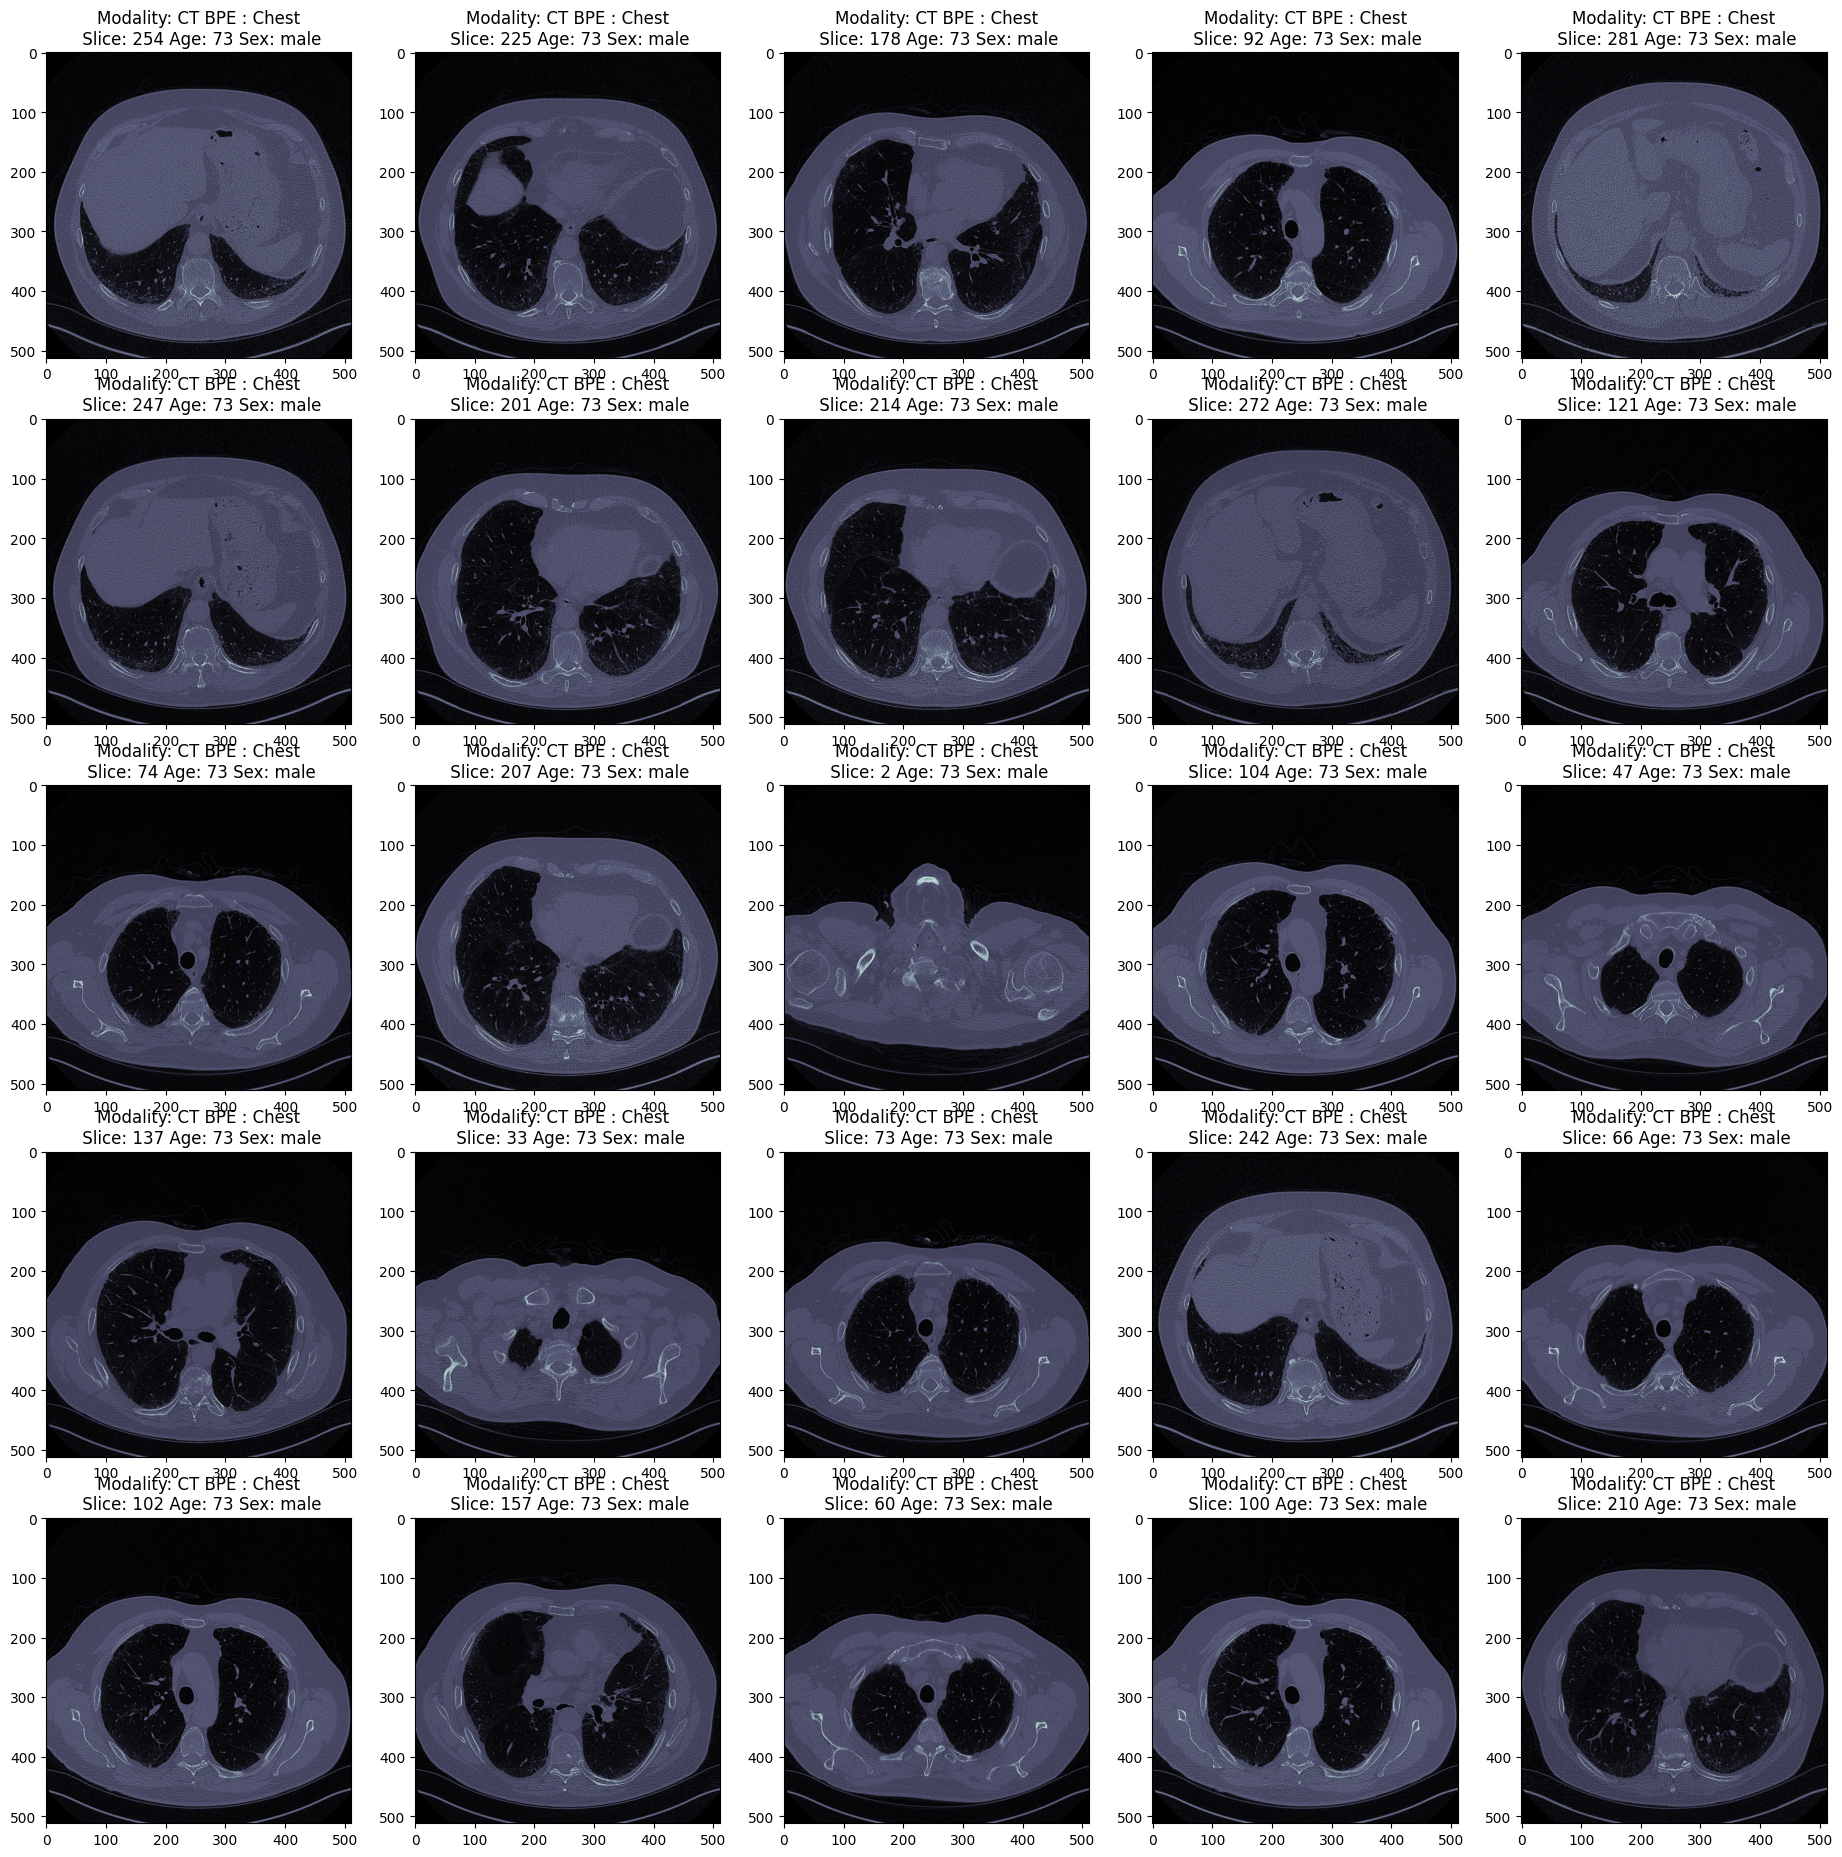

In [ ]:
fig, axs = plt.subplots(5,5, figsize = (23,23))

for i in range(0,25):
  RefDs = pydicom.dcmread(lstFilesDCM[i])
  axs[i//5, i%5].imshow(RefDs.pixel_array, cmap=plt.cm.bone)
  axs[i//5, i%5].set_title('Modality: {} BPE : {}\n Slice: {} Age: {} Sex: {}'. format(df.Modality[i], df.BPE[i], df.Slice[i], df.Age[i], df.Sex[i]))

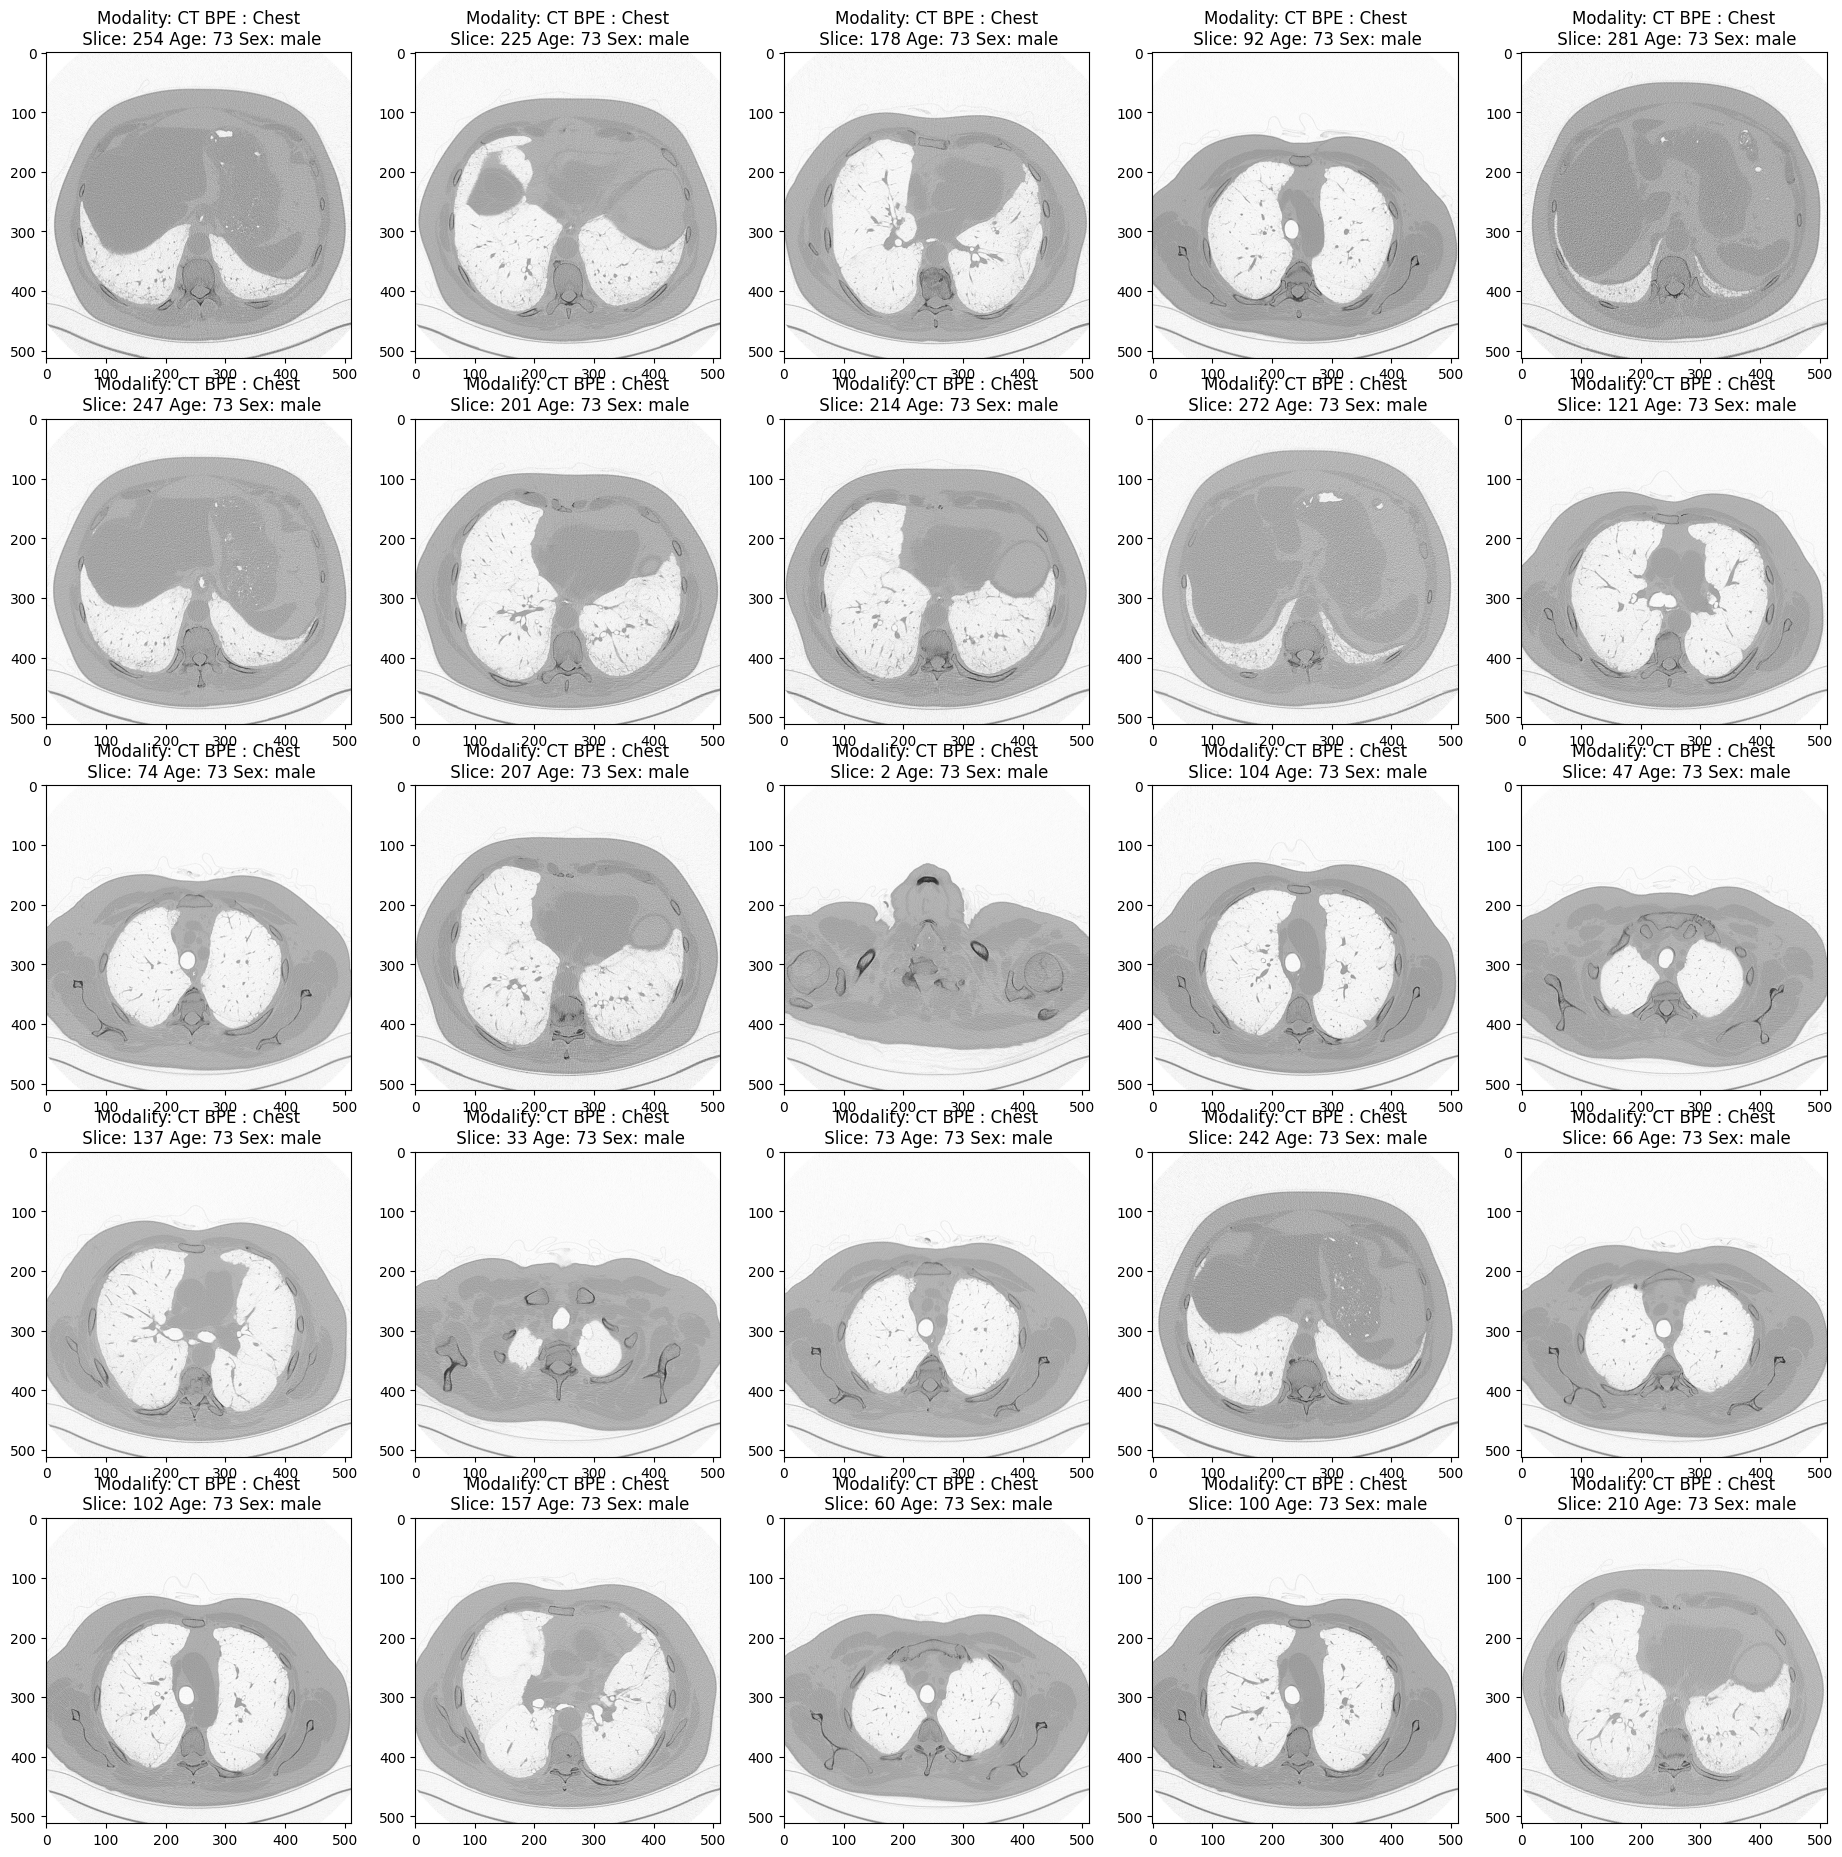

In [ ]:
fig, axs = plt.subplots(5,5, figsize = (23,23))

for i in range(0,25):
  RefDs = pydicom.dcmread(lstFilesDCM[i])
  axs[i//5, i%5].imshow(RefDs.pixel_array, cmap='binary')
  axs[i//5, i%5].set_title('Modality: {} BPE : {}\n Slice: {} Age: {} Sex: {}'. format(df.Modality[i], df.BPE[i], df.Slice[i], df.Age[i], df.Sex[i]))

In [ ]:
train = pd.read_csv(data_path / 'train.csv')
test = pd.read_csv(data_path / 'test.csv')
train.shape, test.shape

((1549, 7), (5, 7))

In [ ]:
train

,Patient,Weeks,FVC,Percent,Age,Sex,SmokingStatus
0,ID00007637202177411956430,-4,2315,58.253649,79,Male,Ex-smoker
1,ID00007637202177411956430,5,2214,55.712129,79,Male,Ex-smoker
2,ID00007637202177411956430,7,2061,51.862104,79,Male,Ex-smoker
3,ID00007637202177411956430,9,2144,53.950679,79,Male,Ex-smoker
4,ID00007637202177411956430,11,2069,52.063412,79,Male,Ex-smoker
...,...,...,...,...,...,...,...
1544,ID00426637202313170790466,13,2712,66.594637,73,Male,Never smoked
1545,ID00426637202313170790466,19,2978,73.126412,73,Male,Never smoked
1546,ID00426637202313170790466,31,2908,71.407524,73,Male,Never smoked
1547,ID00426637202313170790466,43,2975,73.052745,73,Male,Never smoked


In [ ]:
print(train.isna().sum())

Patient          0
Weeks            0
FVC              0
Percent          0
Age              0
Sex              0
SmokingStatus    0
dtype: int64


In [ ]:
print(test.isna().sum())

Patient          0
Weeks            0
FVC              0
Percent          0
Age              0
Sex              0
SmokingStatus    0
dtype: int64


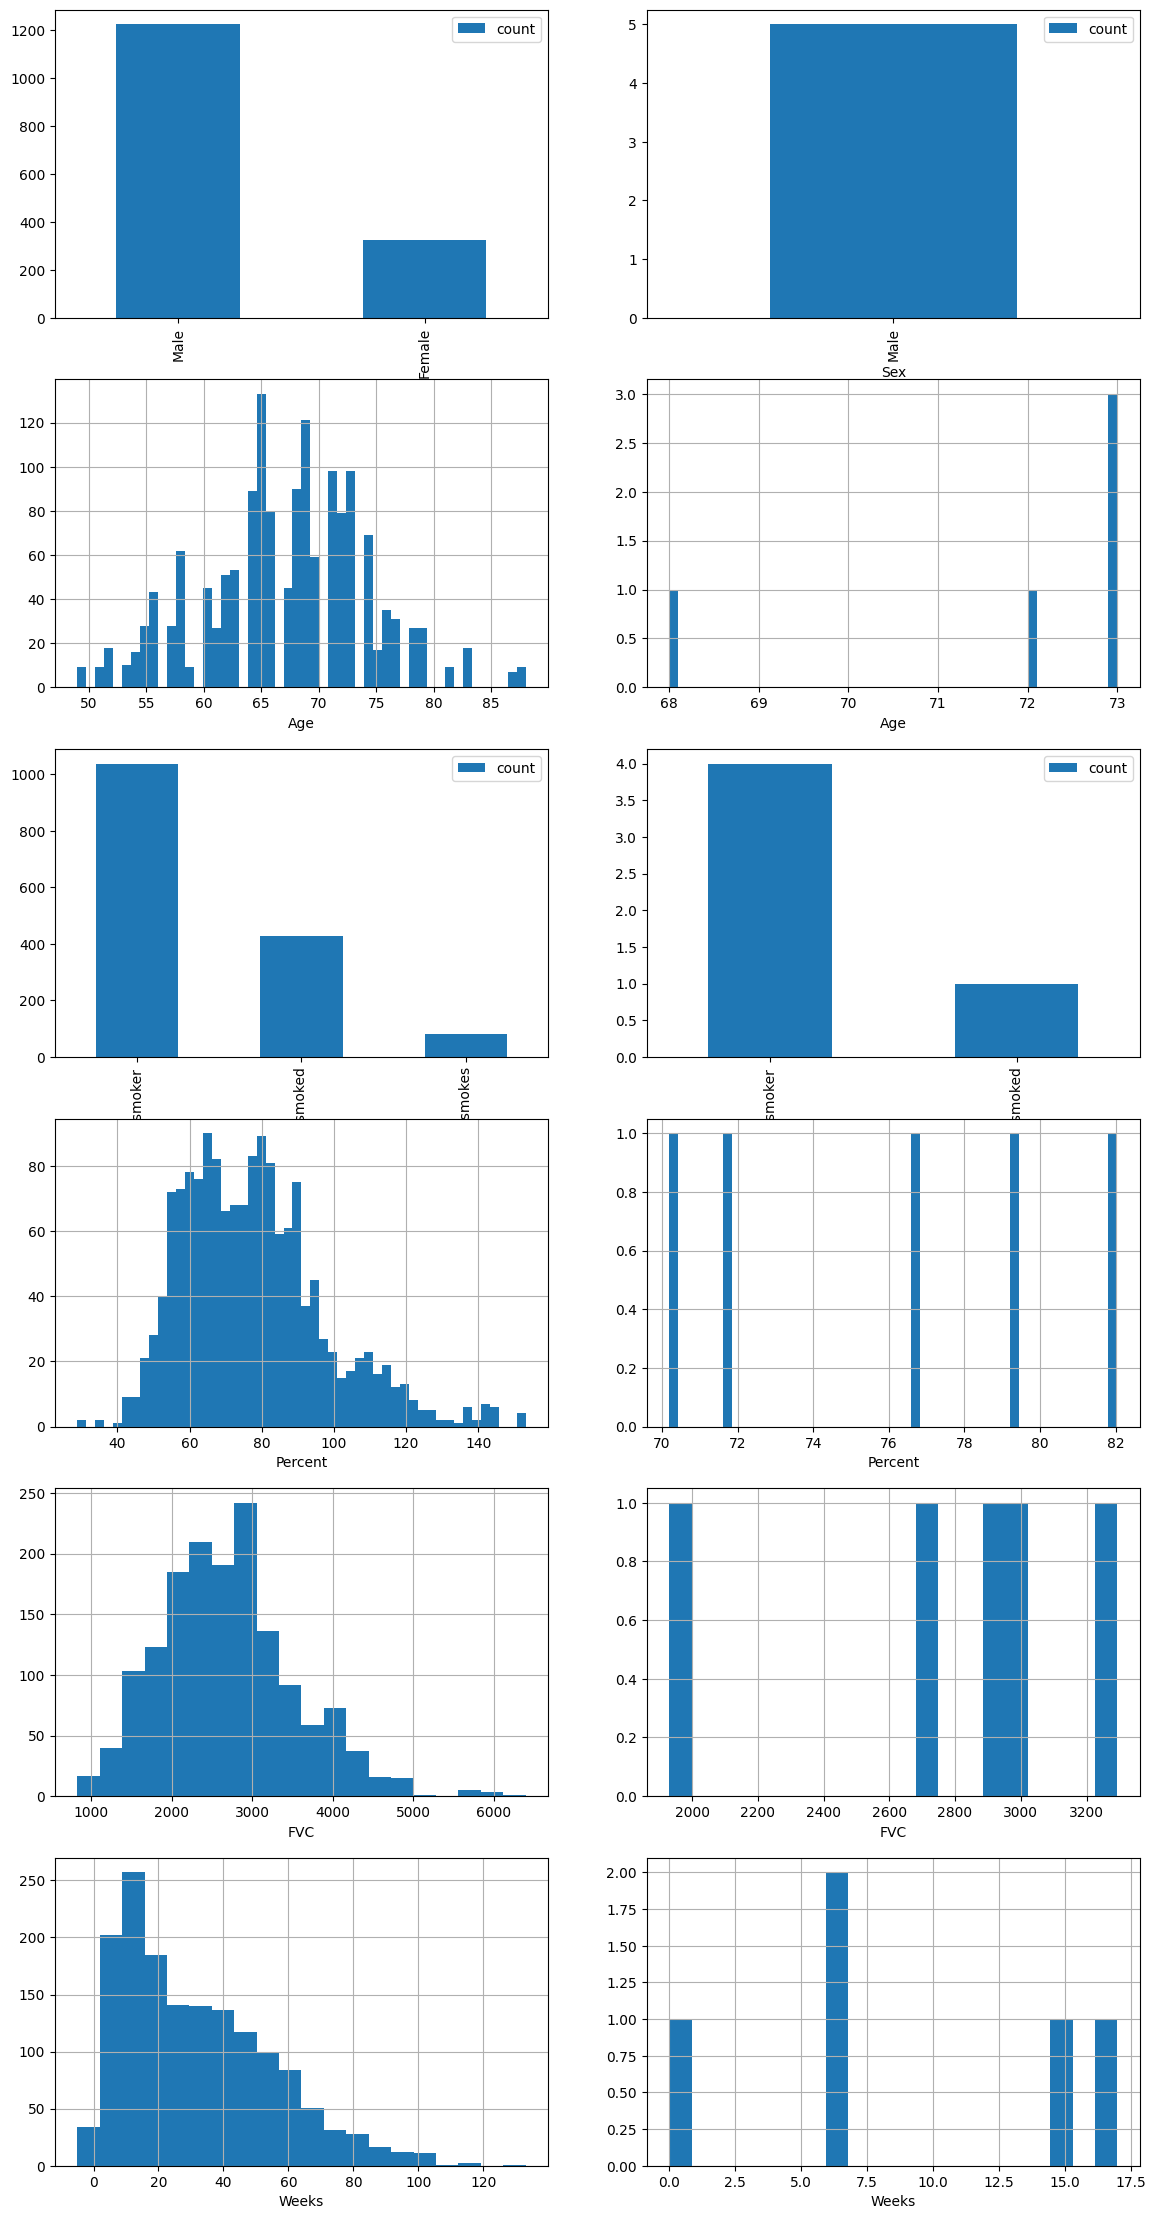

In [ ]:
fig, axs = plt.subplots(6,2, figsize=(14,28))

train['Sex'].value_counts().plot(kind='bar', legend=True, ax=axs[0,0])
test['Sex'].value_counts().plot(kind='bar', legend=True, ax=axs[0,1])

train['Age'].hist(bins=50, ax=axs[1,0])
test['Age'].hist(bins=50, ax=axs[1,1])
axs[1,0].set_xlabel('Age')
axs[1,1].set_xlabel('Age')

train['SmokingStatus'].value_counts().plot(kind='bar', legend=True, ax=axs[2,0])
test['SmokingStatus'].value_counts().plot(kind='bar', legend=True, ax=axs[2,1])

train['Percent'].hist(bins=50, ax=axs[3,0])
test['Percent'].hist(bins=50, ax=axs[3,1])
axs[3,0].set_xlabel('Percent')
axs[3,1].set_xlabel('Percent')

train['FVC'].hist(bins=20, ax=axs[4,0])
test['FVC'].hist(bins=20, ax=axs[4,1])
axs[4,0].set_xlabel('FVC')
axs[4,1].set_xlabel('FVC')

train['Weeks'].hist(bins=20, ax=axs[5,0])
test['Weeks'].hist(bins=20, ax=axs[5,1])
axs[5,0].set_xlabel('Weeks')
axs[5,1].set_xlabel('Weeks')

plt.show()

In [ ]:
len(lstFilesDCM)

34287